# Capítulo 5 · Actividad: ¿cuánto consume este auto?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/02_actividad_mpg_regresion.ipynb)

Entrena una **regresión** que prediga el rendimiento de un auto en **millas por galón** (`mpg`) y consigue el mejor modelo que puedas. Haz todo el proceso que vimos en clase; el preprocesamiento lo decides tú.

| Variable | Significado |
|---|---|
| `mpg` | **Target**: millas por galón (más alto = consume menos) |
| `cylinders` | Número de cilindros |
| `displacement` | Cilindrada del motor (pulgadas cúbicas) |
| `horsepower` | Potencia (caballos de fuerza) |
| `weight` | Peso (libras) |
| `acceleration` | Segundos para ir de 0 a 60 mph |
| `model_year` | Año del modelo (70 = 1970) |
| `origin` | Región de origen: `usa`, `europe` o `japan` |
| `name` | Nombre del auto |

Como mínimo, tu notebook debe incluir:

- Un **modelo lineal base**: coeficientes, métricas de error y $R^2$.
- Los mismos modelos que vimos en clase: regresión simple, lineal múltiple, Ridge, Lasso, polinomial y RANSAC.
- Una **tabla final** comparando los modelos con validación cruzada y test, y tus **conclusiones**: ¿qué modelo elegirías y por qué?

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`

In [98]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.linear_model import Lasso, LinearRegression, RANSACRegressor, Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error, mean_squared_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")
sns.set_theme(style="whitegrid")

# Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

df = pd.read_csv(DATA_DIR / "mpg.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## Vistazo general

In [99]:
print("Filas y columnas:", df.shape)
df.info()

Filas y columnas: (398, 9)
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [100]:
df.describe().round(2)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.00,398.00,398.00,392.00,398.00,398.00,398.00
mean,23.51,5.45,193.43,104.47,2970.42,15.57,76.01
std,7.82,1.70,104.27,38.49,846.84,2.76,3.70
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00
25%,17.50,4.00,104.25,75.00,2223.75,13.82,73.00
50%,23.00,4.00,148.50,93.50,2803.50,15.50,76.00
75%,29.00,8.00,262.00,126.00,3608.00,17.18,79.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00


In [101]:
for col in ["origin", "name"]:
    print(df[col].value_counts(dropna=False), "\n")

origin
usa       249
japan      79
europe     70
Name: count, dtype: int64 

name
ford pinto          6
ford maverick       5
amc matador         5
toyota corolla      5
chevrolet impala    4
                   ..
ford mustang gl     1
vw pickup           1
dodge rampage       1
ford ranger         1
chevy s-10          1
Name: count, Length: 305, dtype: int64 



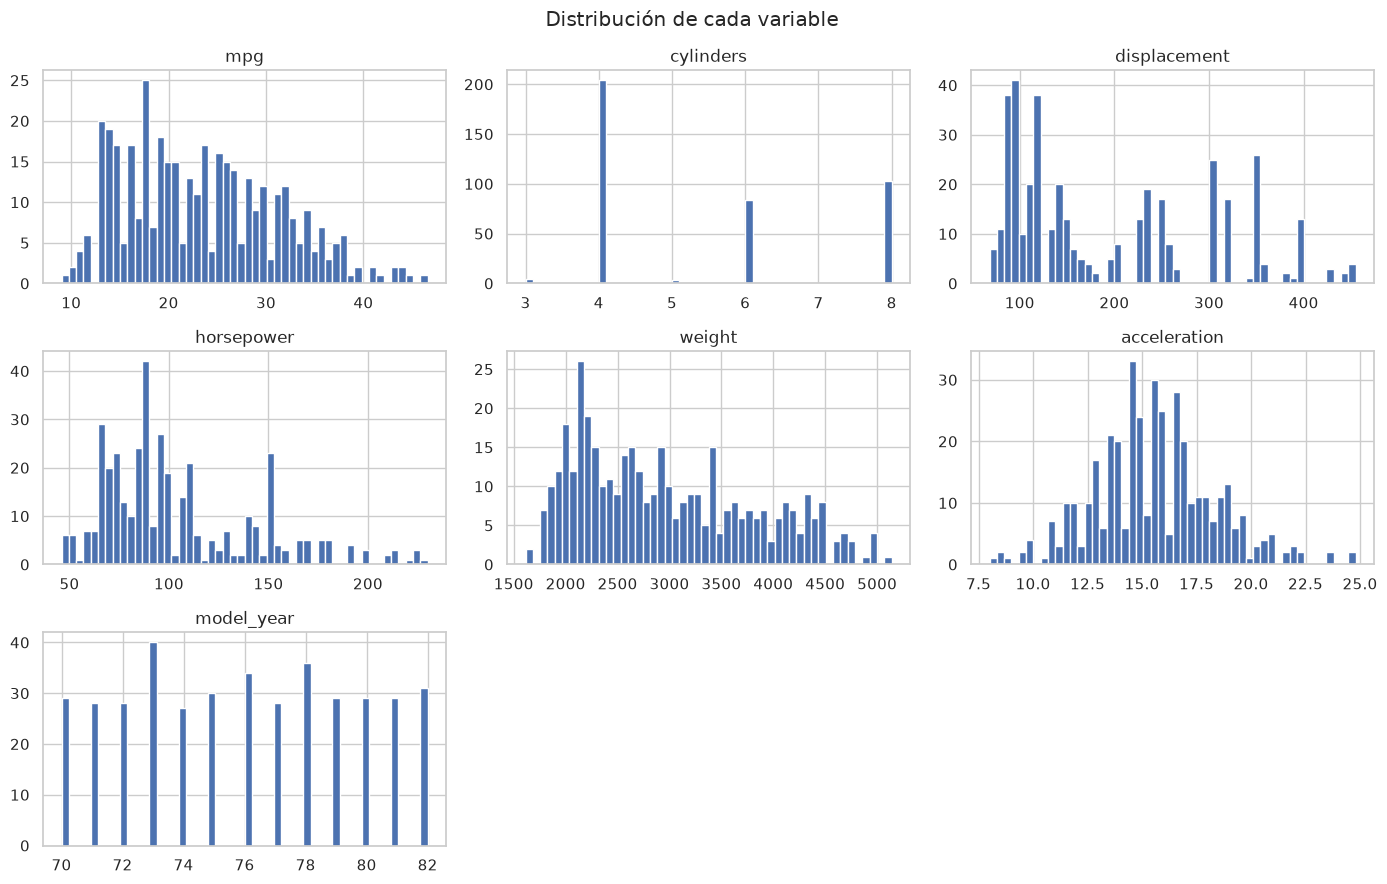

In [102]:
df.hist(bins=50, figsize=(14, 9))
plt.suptitle("Distribución de cada variable")
plt.tight_layout()
plt.show()

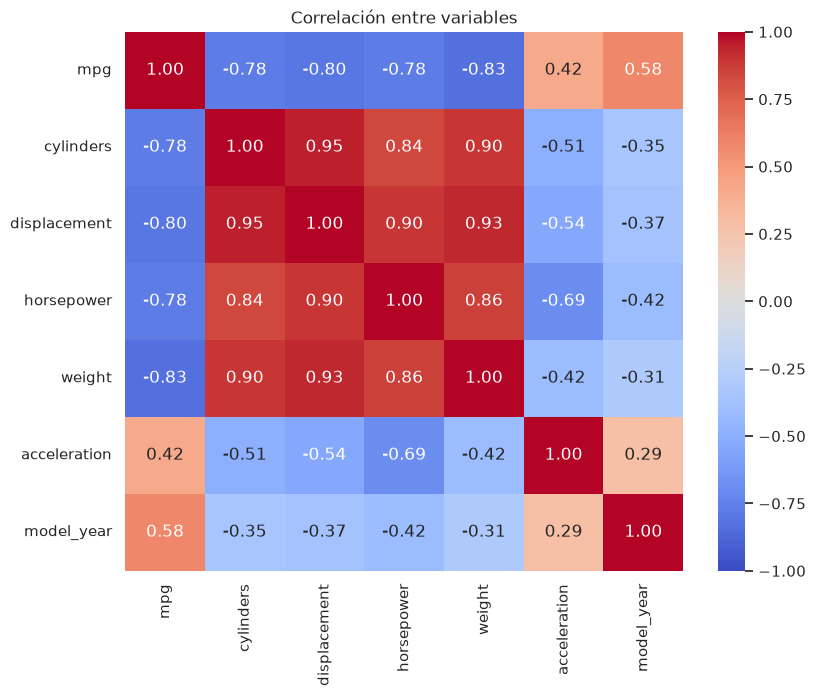

In [103]:
correlaciones = df.drop(columns=["name","origin"]).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
plt.show()

Creo que puedo dropear cylinders o displacement

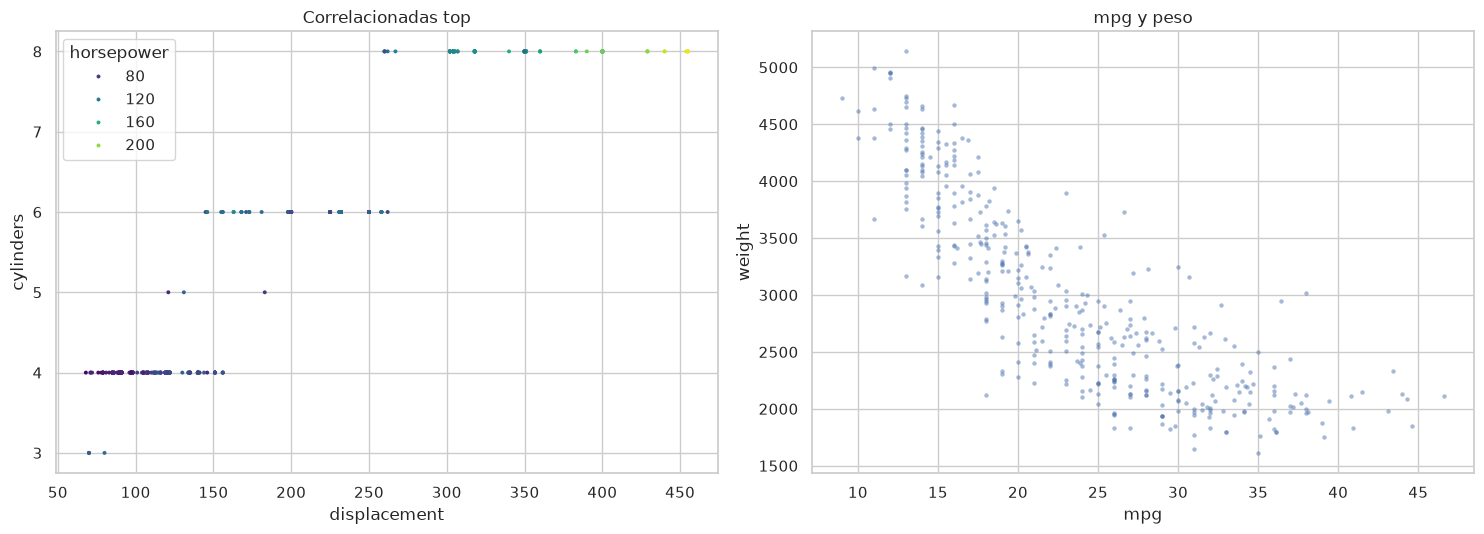

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.scatterplot(data=df, x="displacement", y="cylinders", hue="horsepower", palette="viridis",
                s=8, linewidth=0, ax=axes[0])
axes[0].set_title("Correlacionadas top")

sns.scatterplot(data=df, x="mpg", y="weight", alpha=0.5, s=10, linewidth=0, ax=axes[1])
axes[1].set_title("mpg y peso")
plt.tight_layout()
plt.show()

## Limpieza y preparacion

In [105]:
print("Valores nulos por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores nulos por columna:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Filas duplicadas: 0


Opte por rellenar con la mediana, pero tambien podria hacerlo con la moda en base a ``origin``

In [106]:
df.groupby("cylinders")["horsepower"].median()

cylinders
3     98.5
4     78.0
5     77.0
6    100.0
8    150.0
Name: horsepower, dtype: float64

In [107]:
df["horsepower"] = df["horsepower"].fillna(df.groupby("cylinders")["horsepower"].transform("median"))
print("Nulos en horsepower:", df["horsepower"].isna().sum())

Nulos en horsepower: 0


## Modelos

### Variables

In [ ]:
#X = df.drop(columns=["mpg","origin","name"]) # Todas las numericas
#X = df.drop(columns=["mpg","displacement","origin","name"]) # Sin displacement
X = df.drop(columns=["mpg","cylinders","origin","name"]) # Sin cylinders
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

# Validación cruzada que usaremos durante toda la clase
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (318, 5) | Test: (80, 5)


In [109]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

es_outlier = (X_train < limite_inferior) | (X_train > limite_superior)
es_outlier.sum()

displacement     0
horsepower      11
weight           0
acceleration     5
model_year       0
dtype: int64

In [110]:
X_train_antes = X_train.copy()   # solo para comparar en la gráfica

X_train = X_train.clip(lower=limite_inferior, upper=limite_superior, axis=1)
X_test = X_test.clip(lower=limite_inferior, upper=limite_superior, axis=1)

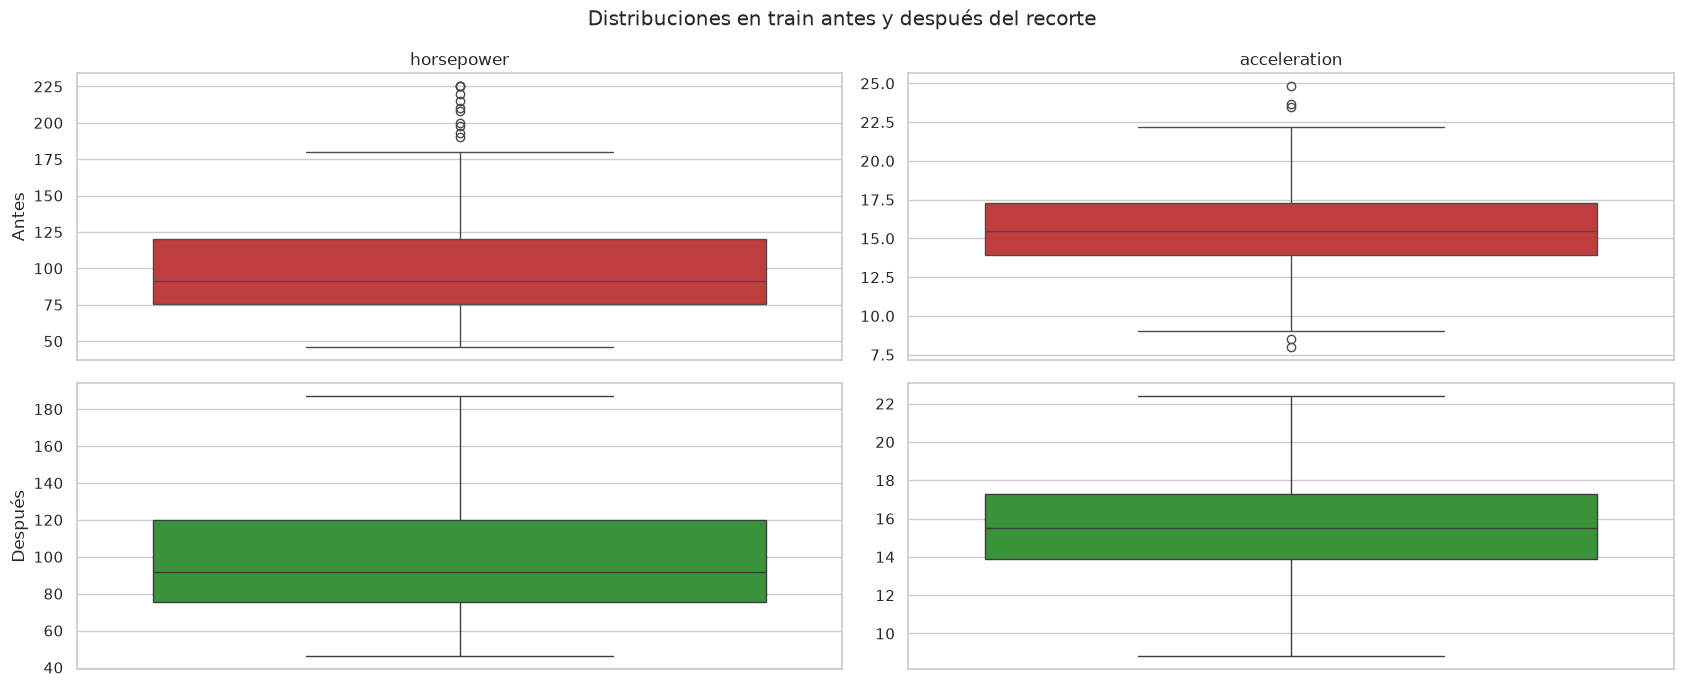

In [111]:
variables_con_outliers = ["horsepower", "acceleration"]

fig, axes = plt.subplots(2, 2, figsize=(17, 7))
for j, variable in enumerate(variables_con_outliers):
    sns.boxplot(y=X_train_antes[variable], ax=axes[0, j], color="tab:red")
    sns.boxplot(y=X_train[variable], ax=axes[1, j], color="tab:green")
    axes[0, j].set_title(variable)
    axes[0, j].set_ylabel("Antes" if j == 0 else "")
    axes[1, j].set_ylabel("Después" if j == 0 else "")
fig.suptitle("Distribuciones en train antes y después del recorte")
plt.tight_layout()
plt.show()

## Regresion lineal Simple

In [112]:
modelo_simple = LinearRegression()
modelo_simple.fit(X_train[["weight"]], y_train)   # doble corchete: X debe ser una tabla, no una columna

beta_0 = modelo_simple.intercept_
beta_1 = modelo_simple.coef_[0]
print(f"Intercepto  β0 = {beta_0:.3f}")
print(f"Pendiente   β1 = {beta_1:.3f}")

Intercepto  β0 = 46.782
Pendiente   β1 = -0.008


Me falta entender la interpretacion de los coeficientes

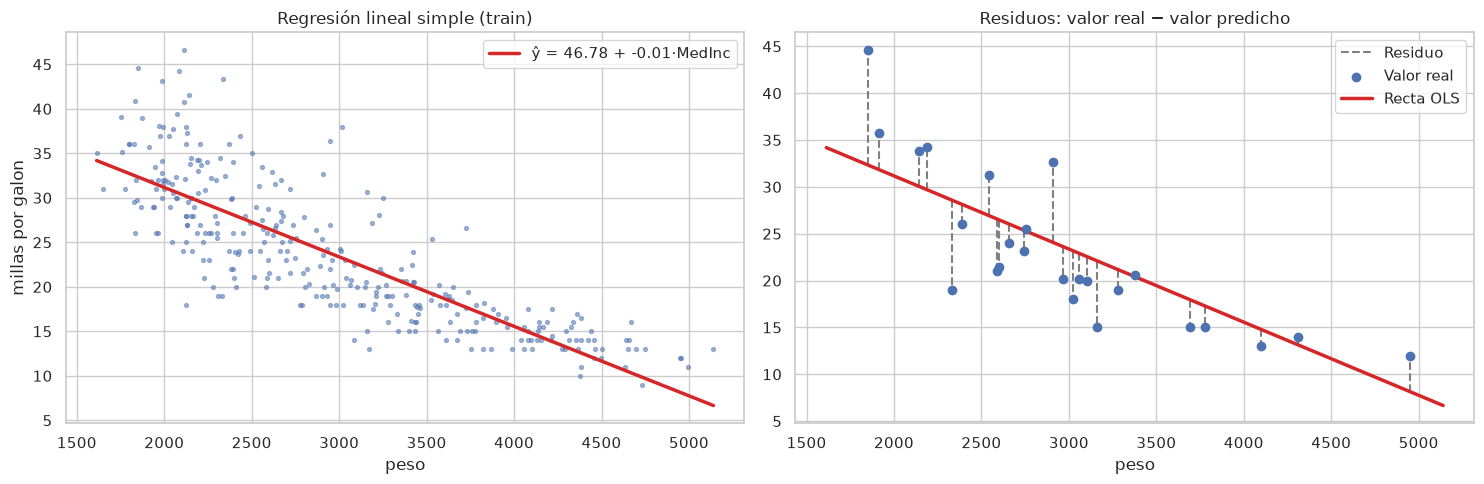

In [113]:
recta_x = pd.DataFrame({"weight": np.linspace(X_train["weight"].min(), X_train["weight"].max(), 100)})
recta_y = modelo_simple.predict(recta_x)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(X_train["weight"], y_train, alpha=0.5, s=8)
axes[0].plot(recta_x["weight"], recta_y, color="tab:red", linewidth=2.5, label=f"ŷ = {beta_0:.2f} + {beta_1:.2f}·MedInc")
axes[0].set_xlabel("peso")
axes[0].set_ylabel("millas por galon")
axes[0].set_title("Regresión lineal simple (train)")
axes[0].legend()

muestra = X_train[["weight"]].sample(25, random_state=SEED)
y_muestra = y_train.loc[muestra.index]
pred_muestra = modelo_simple.predict(muestra)
axes[1].vlines(muestra["weight"], pred_muestra, y_muestra, color="gray", linestyle="--", label="Residuo")
axes[1].scatter(muestra["weight"], y_muestra, zorder=3, label="Valor real")
axes[1].plot(recta_x["weight"], recta_y, color="tab:red", linewidth=2.5, label="Recta OLS")
axes[1].set_xlabel("peso")
axes[1].set_title("Residuos: valor real − valor predicho")
axes[1].legend()
plt.tight_layout()
plt.show()

In [114]:
distritos_nuevos = pd.DataFrame({"weight": [2.0, 5.0, 8.0]})   # 20 000 $, 50 000 $ y 80 000 $
distritos_nuevos["valor_predicho"] = modelo_simple.predict(distritos_nuevos)

# A mano, con la ecuación de la recta: el resultado es el mismo
distritos_nuevos["a_mano"] = beta_0 + beta_1 * distritos_nuevos["weight"]
distritos_nuevos.round(3)

,weight,valor_predicho,a_mano
0,2.0,46.766,46.766
1,5.0,46.743,46.743
2,8.0,46.720,46.720


In [115]:
pred_simple = modelo_simple.predict(X_test[["weight"]])
print(f"R² en test:   {r2_score(y_test, pred_simple):.3f}")
print(f"RMSE en test: {root_mean_squared_error(y_test, pred_simple):.3f}  (cientos de miles de $)")

R² en test:   0.723
RMSE en test: 3.859  (cientos de miles de $)


## Regresion lineal multiple

In [116]:
modelo_lineal = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LinearRegression()),
])
modelo_lineal.fit(X_train, y_train)

pred_lineal = modelo_lineal.predict(X_test)
print(f"R² en test:   {r2_score(y_test, pred_lineal):.3f}   (regresión simple: {r2_score(y_test, pred_simple):.3f})")
print(f"RMSE en test: {root_mean_squared_error(y_test, pred_lineal):.3f}   (regresión simple: {root_mean_squared_error(y_test, pred_simple):.3f})")

R² en test:   0.826   (regresión simple: 0.723)
RMSE en test: 3.055   (regresión simple: 3.859)


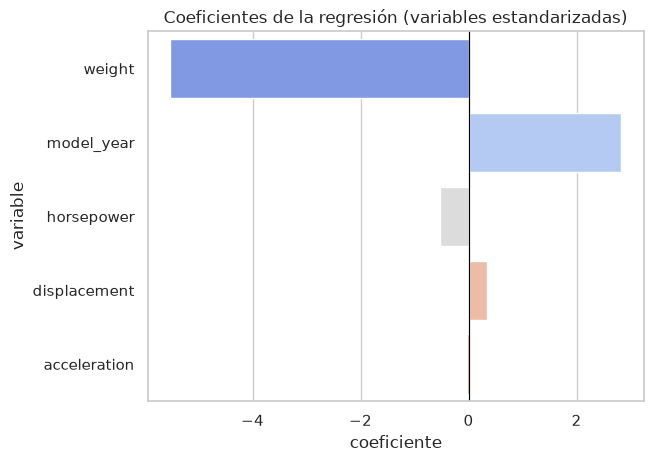

,variable,coeficiente
2,weight,-5.523
4,model_year,2.827
1,horsepower,-0.536
0,displacement,0.334
3,acceleration,-0.036


In [117]:
coeficientes = pd.DataFrame({
    "variable": X_train.columns,
    "coeficiente": modelo_lineal.named_steps["regresion"].coef_,
}).sort_values("coeficiente", key=abs, ascending=False)

ax = sns.barplot(data=coeficientes, x="coeficiente", y="variable", hue="variable", palette="coolwarm")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Coeficientes de la regresión (variables estandarizadas)")
plt.show()

coeficientes.round(3)

In [118]:
def metricas_regresion(y_real, y_pred, n_variables):
    "Métricas principales de una regresión."
    n = len(y_real)
    r2 = r2_score(y_real, y_pred)
    return {
        "MSE": mean_squared_error(y_real, y_pred),
        "RMSE": root_mean_squared_error(y_real, y_pred),
        "MAE": mean_absolute_error(y_real, y_pred),
        "MAPE": mean_absolute_percentage_error(y_real, y_pred),
        "R²": r2,
        "R² ajustado": 1 - (1 - r2) * (n - 1) / (n - n_variables - 1),
        "Correlación(y, ŷ)": np.corrcoef(y_real, y_pred)[0, 1],
    }


pd.DataFrame({
    "Simple (MedInc)": metricas_regresion(y_test, pred_simple, n_variables=1),
    "Múltiple (8 variables)": metricas_regresion(y_test, pred_lineal, n_variables=8),
}).round(3)

,Simple (MedInc),Múltiple (8 variables)
MSE,14.895,9.333
RMSE,3.859,3.055
MAE,3.118,2.461
MAPE,0.143,0.124
R²,0.723,0.826
R² ajustado,0.719,0.807
"Correlación(y, ŷ)",0.855,0.915


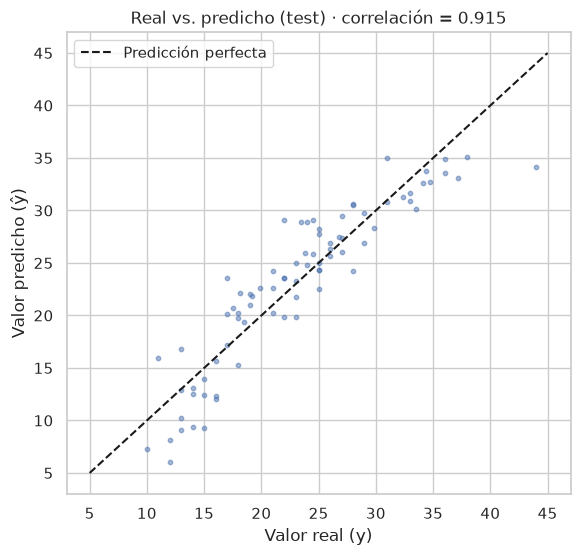

In [119]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, pred_lineal, alpha=0.5, s=10)
ax.plot([5, 45], [5, 45], "k--", label="Predicción perfecta")
ax.set_xlabel("Valor real (y)")
ax.set_ylabel("Valor predicho (ŷ)")
ax.set_title(f"Real vs. predicho (test) · correlación = {np.corrcoef(y_test, pred_lineal)[0, 1]:.3f}")
ax.legend()
plt.show()

In [122]:
modelos = {
    "Simple (weight)": LinearRegression(),
    "Lineal múltiple": modelo_lineal,
    "Ridge": Pipeline([("escalador", StandardScaler()), ("regresion", Ridge(alpha=1.0))]),
    "Lasso": Pipeline([("escalador", StandardScaler()), ("regresion", Lasso(alpha=0.01))]),
    "Polinomial (grado 2)": Pipeline([
        ("escalador", StandardScaler()),
        ("poli", PolynomialFeatures(degree=2, include_bias=False)),
        ("escalador_poli", StandardScaler()),
        ("regresion", LinearRegression()),
    ]),
    "RANSAC": Pipeline([("escalador", StandardScaler()),
                        ("regresion", RANSACRegressor(LinearRegression(), random_state=SEED))]),
}

filas = []
predicciones = {}
for nombre, modelo in modelos.items():
    columnas = ["weight"] if nombre.startswith("Simple") else list(X_train.columns)
    cv_res = cross_validate(modelo, X_train[columnas], y_train, cv=cv,
                            scoring="neg_root_mean_squared_error", return_train_score=True)
    modelo.fit(X_train[columnas], y_train)
    pred = modelo.predict(X_test[columnas])
    fila = {"modelo": nombre,
            "RMSE train (CV)": -cv_res["train_score"].mean(),
            "RMSE validación (CV)": -cv_res["test_score"].mean(),
            "RMSE validación (desv.)": cv_res["test_score"].std()}
    fila.update({f"{metrica} test": valor
                 for metrica, valor in metricas_regresion(y_test, pred, n_variables=len(columnas)).items()})
    filas.append(fila)
    predicciones[nombre] = pred

reporte = pd.DataFrame(filas).set_index("modelo")
reporte.drop(columns=["MSE test", "R² ajustado test"]).round(3)

,RMSE train (CV),RMSE validación (CV),RMSE validación (desv.),RMSE test,MAE test,MAPE test,R² test,"Correlación(y, ŷ) test"
modelo,,,,,,,,
Simple (weight),4.442,4.493,0.193,3.859,3.118,0.143,0.723,0.855
Lineal múltiple,3.494,3.586,0.199,3.055,2.461,0.124,0.826,0.915
Ridge,3.495,3.580,0.202,3.051,2.457,0.124,0.827,0.915
Lasso,3.494,3.578,0.198,3.055,2.458,0.124,0.826,0.915
Polinomial (grado 2),2.736,3.010,0.221,2.507,1.816,0.085,0.883,0.944
RANSAC,3.772,3.791,0.384,3.181,2.472,0.122,0.812,0.905


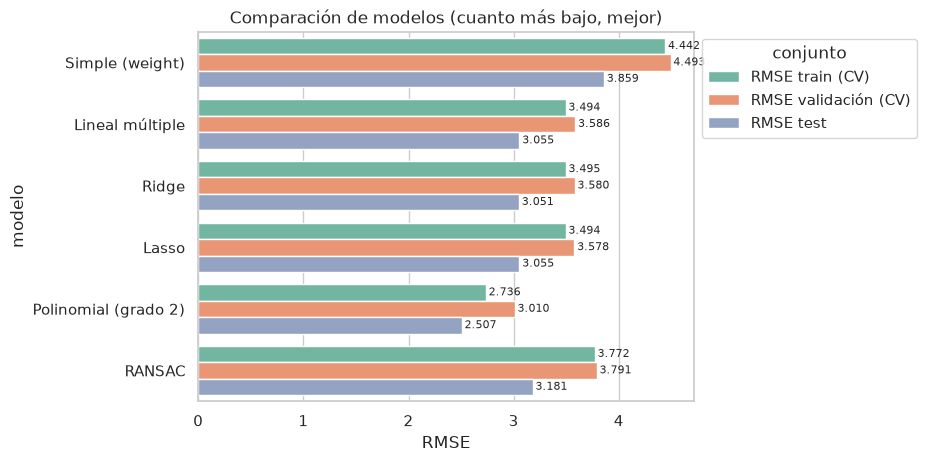

In [123]:
reporte_largo = (reporte[["RMSE train (CV)", "RMSE validación (CV)", "RMSE test"]]
                 .reset_index()
                 .melt(id_vars="modelo", var_name="conjunto", value_name="RMSE"))

ax = sns.barplot(data=reporte_largo, x="RMSE", y="modelo", hue="conjunto", palette="Set2")
ax.set_title("Comparación de modelos (cuanto más bajo, mejor)")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", fontsize=8, padding=2)
plt.show()

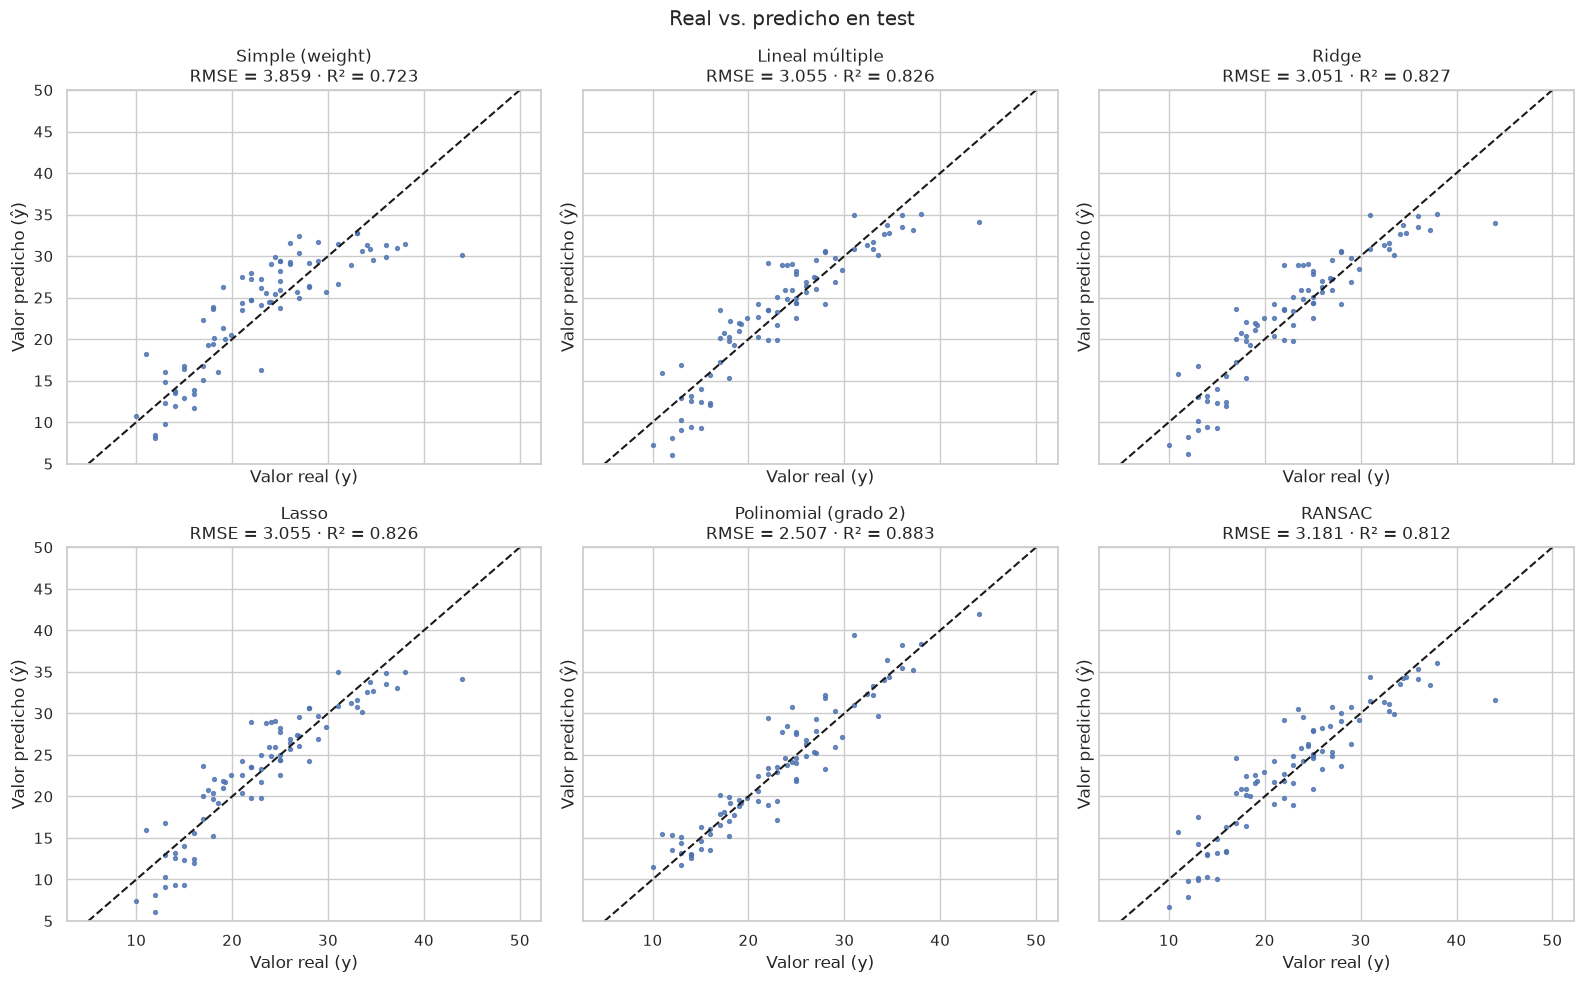

In [129]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=True)
for (nombre, pred), ax in zip(predicciones.items(), axes.flat):
    ax.scatter(y_test, pred, alpha=0.8, s=8)
    ax.plot([5, 50], [5, 50], "k--")
    ax.set_title(f"{nombre}\nRMSE = {root_mean_squared_error(y_test, pred):.3f} · R² = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Valor real (y)")
    ax.set_ylabel("Valor predicho (ŷ)")
ax.set_ylim(5, 50)
fig.suptitle("Real vs. predicho en test")
plt.tight_layout()
plt.show()